# Classification uncertainty in 2D

Signal vs background in a 2D feature plane. We will visualize the true class posterior, the decision boundary, the aleatoric/epistemic entropy decomposition, miscalibration and its repairs (temperature scaling and **isotonic regression**, both implemented from scratch). 

The toy is fully analytic, both class densities are Gaussian mixtures, so the true posterior $p(1\mid x)$, the true entropy map, and the true likelihood ratio $p_1/p_0$ are all available in closed form. Three ingredients, one per lesson:

- **overlapping classes** $\to$ genuine aleatoric uncertainty (a band of irreducible ambiguity along the boundary);
- a **training gap** (a region removed from the training sample only) $\to$ epistemic uncertainty where the boundary was never constrained;
- a deliberately **over-trained network** (small sample, no weight decay, many epochs) $\to$ honest over-confidence for the calibration section to repair.


## 0. The toy: a spiral against a ring

Background (class 0): Gaussian noise around a **spiral** arm. Signal (class 1): Gaussian noise around a **ring** that cuts through the spiral — so the two classes braid and genuinely overlap wherever the ring crosses an arm. Both densities are *curve convolutions*, $p(x) = \int \mathcal{N}(x; c(t), \sigma^2 I)\,p(t)\,dt$,
which we evaluate by exact quadrature over a dense $t$-grid. So the true posterior, the true entropy map and the true likelihood ratio remain available.

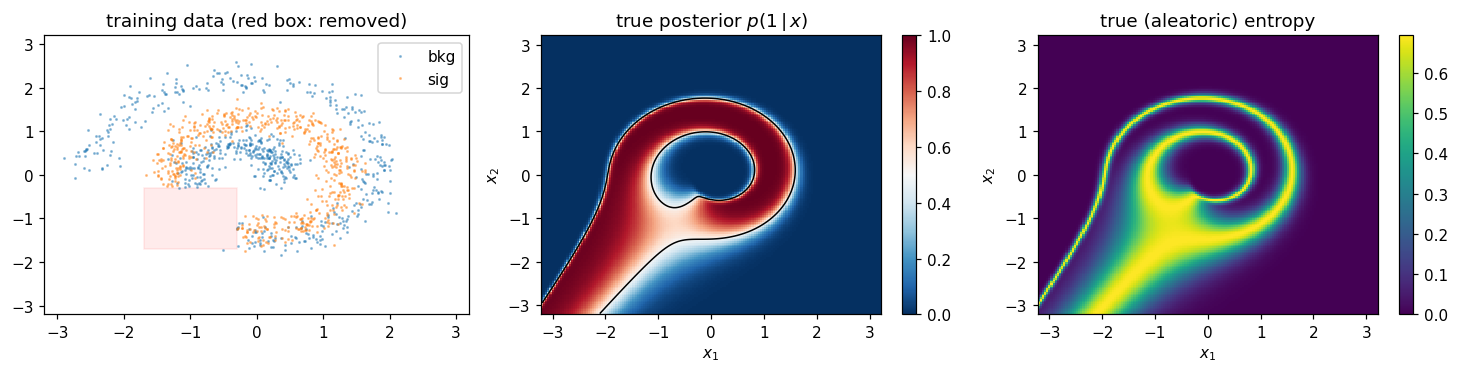

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

rng = np.random.default_rng(0); torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (7, 3); plt.rcParams["figure.dpi"] = 110

# --- class densities: Gaussian tubes around parametric curves, exact by quadrature ---
T_SP = np.linspace(0.0, 3.0 * np.pi, 700)                     # spiral parameter grid
SPIRAL = np.stack([(0.30 + 0.24 * T_SP) * np.cos(T_SP),
                   (0.30 + 0.24 * T_SP) * np.sin(T_SP)], 1)
SIG_SP = 0.18
TH = np.linspace(-np.pi, np.pi, 700, endpoint=False)          # ring parameter grid
RING = 1.3 * np.stack([np.cos(TH), np.sin(TH)], 1)
SIG_RING = 0.18

def _curve_logpdf(x, curve, sig):
    """log p(x) for x = c(t) + sig*noise, t uniform on the grid: logsumexp over the grid."""
    d2 = ((x[:, None, :] - curve[None, :, :]) ** 2).sum(-1)   # (n, M)
    a = -0.5 * d2 / sig ** 2
    m = a.max(axis=1, keepdims=True)
    return (m[:, 0] + np.log(np.exp(a - m).mean(axis=1))) - np.log(2 * np.pi * sig ** 2)

def log_p0(x): return _curve_logpdf(np.asarray(x, np.float64), SPIRAL, SIG_SP)   # background: spiral
def log_p1(x): return _curve_logpdf(np.asarray(x, np.float64), RING, SIG_RING)   # signal: ring

def true_posterior(x, pi1=0.5):          # Bayes' theorem, exact
    lr = np.exp(np.clip(log_p1(x) - log_p0(x), -500, 500))
    return pi1 * lr / (1 - pi1 + pi1 * lr)

GAP = dict(x1=(-1.7, -0.3), x2=(-1.7, -0.3))  # removed from TRAINING only: covers a spiral/ring crossing

def simulate(n, rng, with_gap=False):
    y = (rng.random(n) < 0.5).astype(np.float32)
    x = np.empty((n, 2), np.float32)
    nb_ = int((~y.astype(bool)).sum())
    t = rng.uniform(0.0, 3.0 * np.pi, nb_)
    x[~y.astype(bool)] = (np.stack([(0.30 + 0.24 * t) * np.cos(t),
                                    (0.30 + 0.24 * t) * np.sin(t)], 1)
                          + SIG_SP * rng.standard_normal((nb_, 2)))
    ns_ = int(y.sum())
    th = rng.uniform(-np.pi, np.pi, ns_)
    x[y.astype(bool)] = (1.3 * np.stack([np.cos(th), np.sin(th)], 1)
                         + SIG_RING * rng.standard_normal((ns_, 2)))
    if with_gap:
        keep = ~((x[:, 0] > GAP["x1"][0]) & (x[:, 0] < GAP["x1"][1]) &
                 (x[:, 1] > GAP["x2"][0]) & (x[:, 1] < GAP["x2"][1]))
        x, y = x[keep], y[keep]
    return x.astype(np.float32), y

x_tr, y_tr = simulate(1_500, rng, with_gap=True)      # SMALL + gapped: on purpose
x_cal, y_cal = simulate(4_000, rng)
x_te, y_te = simulate(40_000, rng)

g1 = np.linspace(-3.2, 3.2, 160); g2 = np.linspace(-3.2, 3.2, 160)
G1, G2 = np.meshgrid(g1, g2, indexing="ij")
GRID = np.stack([G1.ravel(), G2.ravel()], 1).astype(np.float32)
P_TRUE = true_posterior(GRID).reshape(G1.shape)
H = lambda p: -(p * np.log(p + 1e-12) + (1 - p) * np.log(1 - p + 1e-12))

def show(ax, Mp, title, **kw):
    im = ax.pcolormesh(g1, g2, Mp.T, **kw); plt.colorbar(im, ax=ax)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.5))
ax[0].plot(*x_tr[y_tr == 0].T, ".", ms=2, alpha=0.4, label="bkg")
ax[0].plot(*x_tr[y_tr == 1].T, ".", ms=2, alpha=0.4, label="sig")
ax[0].add_patch(plt.Rectangle((GAP["x1"][0], GAP["x2"][0]),
                np.diff(GAP["x1"])[0], np.diff(GAP["x2"])[0], fc="r", alpha=0.08, ec="r"))
ax[0].legend(); ax[0].set(title="training data (red box: removed)", xlim=(-3.2, 3.2), ylim=(-3.2, 3.2))
show(ax[1], P_TRUE, "true posterior $p(1\\,|\\,x)$", cmap="RdBu_r", vmin=0, vmax=1)
ax[1].contour(g1, g2, P_TRUE.T, levels=[0.5], colors="k", linewidths=1)
show(ax[2], H(P_TRUE), "true (aleatoric) entropy", cmap="viridis")
plt.tight_layout()

Read the right panel before fitting anything: the bright band **is** the aleatoric uncertainty — irreducible class overlap, a property of the problem. No training procedure can remove it, and a good classifier should *report* it, not fight it.

## 1. One over-trained network: confident and wrong(ly calibrated)

Small sample, no weight decay, long training: the recipe for over-confidence. The probability map will look like a *sharpened* version of the truth — the boundary roughly right, the probabilities saturated toward 0/1.

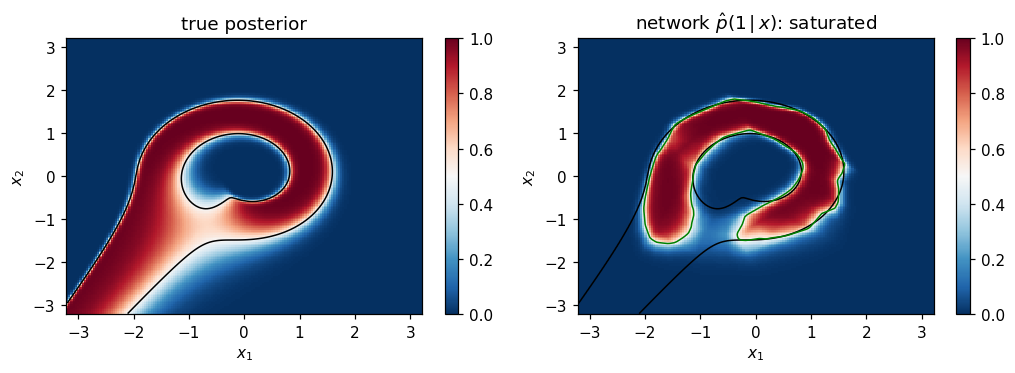

In [2]:
def mlp(n_in, n_out, hidden=64, depth=3):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.ReLU()]; d = hidden
    return nn.Sequential(*(layers + [nn.Linear(d, n_out)]))

def train_cls(model, x, y, epochs=300, lr=1e-3, batch=256, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=0.0)   # no WD: overfit on purpose
    x, y = torch.as_tensor(x), torch.as_tensor(y)
    for ep in range(epochs):
        perm = torch.randperm(x.shape[0])
        for i in range(0, x.shape[0], batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(model(x[idx]).squeeze(-1), y[idx]).backward()
            opt.step()
    return model

def logits(model, x):
    with torch.no_grad():
        return model(torch.as_tensor(x)).squeeze(-1).numpy()

net = train_cls(mlp(2, 1), x_tr, y_tr)
sigmoid = lambda z: np.where(z >= 0, 1/(1 + np.exp(-np.abs(z))), np.exp(-np.abs(z))/(1 + np.exp(-np.abs(z))))
p_grid = sigmoid(logits(net, GRID)).reshape(G1.shape)

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.5))
show(ax[0], P_TRUE, "true posterior", cmap="RdBu_r", vmin=0, vmax=1)
show(ax[1], p_grid, "network $\\hat p(1\\,|\\,x)$: saturated", cmap="RdBu_r", vmin=0, vmax=1)
for a in ax: a.contour(g1, g2, P_TRUE.T, levels=[0.5], colors="k", linewidths=1)
ax[1].contour(g1, g2, p_grid.T, levels=[0.5], colors="g", linewidths=1)
plt.tight_layout()

## 2. The entropy decomposition, as maps

Ensemble of 5; then (BALD equation):
$$\underbrace{\mathbb{H}[\bar p]}_{\text{total}} = \underbrace{\mathbb{E}_m \mathbb{H}[\hat p_m]}_{\text{aleatoric}} + \underbrace{\mathcal{I}(y; m)}_{\text{epistemic}}$$
Predictions to check against the plots: the **aleatoric** map should reproduce the true-entropy band along the boundary (compare to Part 0); the **epistemic** map should light up in the red box — where the members were free to disagree about the boundary — and toward the data-free corners. 

**EXERCISE:** find the pixel with the highest mutual information and plot the 5 members' probabilities there — you should see confident disagreement, not shared ambiguity.

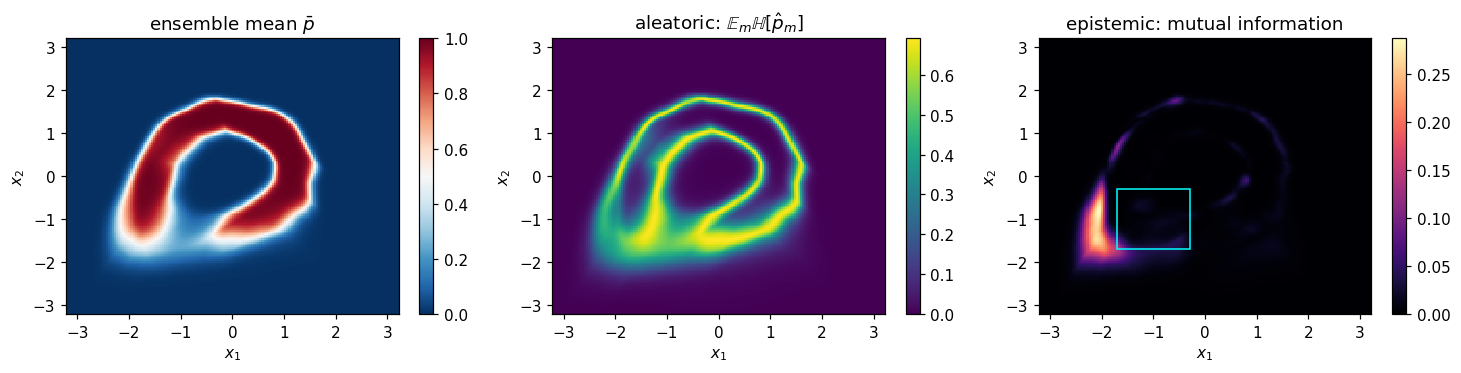

In [3]:
members = [train_cls(mlp(2, 1), x_tr, y_tr, seed=m) for m in range(5)]
P_m = np.stack([sigmoid(logits(m, GRID)) for m in members])                 # (5, npix)
p_bar = P_m.mean(0)
total = H(p_bar); alea = H(P_m).mean(0); mi = total - alea

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.5))
show(ax[0], p_bar.reshape(G1.shape), "ensemble mean $\\bar p$", cmap="RdBu_r", vmin=0, vmax=1)
show(ax[1], alea.reshape(G1.shape), "aleatoric: $\\mathbb{E}_m\\mathbb{H}[\\hat p_m]$", cmap="viridis")
show(ax[2], mi.reshape(G1.shape), "epistemic: mutual information", cmap="magma")
ax[2].add_patch(plt.Rectangle((GAP["x1"][0], GAP["x2"][0]),
                np.diff(GAP["x1"])[0], np.diff(GAP["x2"])[0], fill=False, ec="cyan"))
plt.tight_layout()

## 3. Calibration: reliability, temperature, and isotonic regression 

The reliability diagram will show the over-confidence the training recipe built in. Two repairs, both post-hoc on the calibration set, both from scratch:

- **Temperature scaling**: one scalar $T$, $\hat p = \sigma(z/T)$, fitted by NLL. Cannot change the argmax; cannot overfit; cannot fix input-dependent miscalibration.
- **Isotonic regression**: a *nonparametric monotone* map from raw score to calibrated probability, fitted by the **Pool Adjacent Violators** algorithm — sort the calibration events by score, then repeatedly merge adjacent blocks whose empirical class-1 fractions violate monotonicity, until the sequence of block means is non-decreasing. That step function *is* the calibrated probability. More flexible than $T$ (it can bend differently in different score ranges), at the price of needing more calibration data and being able to overfit small samples — the classic flexibility trade-off, in miniature.

Grade all three (raw / $T$ / isotonic) with proper scores (NLL, Brier) plus ECE and accuracy. 

fitted temperature T = 1.73  (T > 1: the net was over-confident)

variant            NLL   Brier     ECE     acc
raw             0.3895  0.1243  0.0662  0.8254
temperature     0.3548  0.1171  0.0553  0.8254
isotonic        0.3403  0.1122  0.0138  0.8260


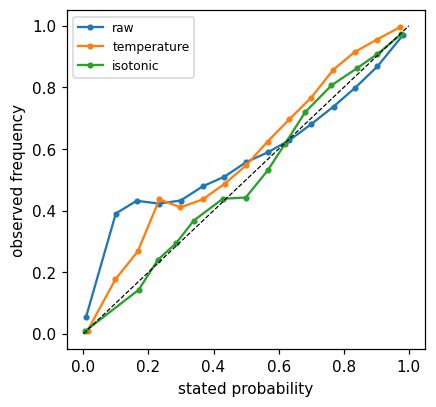

In [4]:
z_cal, z_te = logits(net, x_cal), logits(net, x_te)
sigmoid = lambda z: np.where(z >= 0, 1/(1 + np.exp(-np.abs(z))), np.exp(-np.abs(z))/(1 + np.exp(-np.abs(z))))

# --- temperature scaling: 1D NLL scan ---
def nll_bin(p, y): return float(-(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean())
Ts = np.linspace(0.3, 8.0, 400)
T = Ts[np.argmin([nll_bin(sigmoid(z_cal / t), y_cal) for t in Ts])]
print(f"fitted temperature T = {T:.2f}  (T > 1: the net was over-confident)")

# --- isotonic regression via Pool Adjacent Violators ---
def pav_fit(scores, labels):
    order = np.argsort(scores)
    s, y = scores[order], labels[order].astype(float)
    val, wgt = list(y), [1.0] * len(y)            # one block per event, then merge
    i = 0
    vals, wgts = [], []
    for v, w in zip(val, wgt):
        vals.append(v); wgts.append(w)
        while len(vals) > 1 and vals[-2] >= vals[-1]:          # violation: merge blocks
            w2 = wgts[-1] + wgts[-2]
            v2 = (vals[-1] * wgts[-1] + vals[-2] * wgts[-2]) / w2
            vals = vals[:-2] + [v2]; wgts = wgts[:-2] + [w2]
    fitted = np.repeat(vals, [int(w) for w in wgts])           # step function on cal points
    return s, np.clip(fitted, 1e-4, 1 - 1e-4)

s_knots, p_knots = pav_fit(z_cal, y_cal)
iso = lambda z: np.interp(z, s_knots, p_knots)

# --- grade the three ---
def ece(p, y, bins=15):
    edges = np.linspace(0, 1, bins + 1); out, n = 0.0, len(y)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum(): out += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return out

variants = {"raw": sigmoid(z_te), "temperature": sigmoid(z_te / T), "isotonic": iso(z_te)}
print(f"\n{'variant':<14}{'NLL':>8}{'Brier':>8}{'ECE':>8}{'acc':>8}")
for name, p in variants.items():
    print(f"{name:<14}{nll_bin(p, y_te):>8.4f}{((p - y_te) ** 2).mean():>8.4f}"
          f"{ece(p, y_te):>8.4f}{((p > 0.5) == y_te).mean():>8.4f}")

# --- reliability diagrams ---
def reliability(p, y, bins=15):
    edges = np.linspace(0, 1, bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum() > 50: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

plt.figure(figsize=(4.2, 4))
for name, p in variants.items():
    plt.plot(*reliability(p, y_te), "o-", ms=3, label=name)
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("stated probability"); plt.ylabel("observed frequency"); plt.legend(fontsize=8);

## 4. The payoff: the classifier is a likelihood ratio

The ratio trick: $\;\hat r(x) = \dfrac{\hat p(1\mid x)}{1-\hat p(1\mid x)}$ (priors are 50/50 here). Since this toy has the **analytic** ratio $r = p_1/p_0$, we can do what no real analysis can: plot $\log\hat r$ against $\log r_\mathrm{true}$ event by event. The raw network's points bend away from the diagonal — too extreme on both sides, the *signature of over-confidence transferred to the ratio*. Watch how the three calibration variants move the cloud, then read the closure numbers below with care. **Calibration is not cosmetics: it is the correctness of the ratio** — and of everything built on it (reweighting, NRE).

No variant nails $\mathbb{E}_{\rm bkg}[\hat r] = 1$. The raw net inflates it (over-confidence transferred to the ratio); temperature, a single global knob fitted on *average* NLL, over-corrects it; isotonic wins every binwise metric — look at its ECE — and still misses closure, because the closure expectation is dominated by the rare background events assigned the largest $\hat r$, exactly where every binwise calibration has the least data. The general lesson: *calibrate and validate the functional you will actually use*. 


**EXERCISE:** compute the mean of $\hat r$ over background test events for the three variants. For the true ratio this expectation is exactly 1 ($\int p_0\, p_1/p_0 = 1$, the "ratio closure" test usable on real data where the truth is unknown). How far off is the raw network?

raw            E_bkg[r_hat] = 2.148   (exact ratio gives 1)
temperature    E_bkg[r_hat] = 0.492   (exact ratio gives 1)
isotonic       E_bkg[r_hat] = 2.486   (exact ratio gives 1)


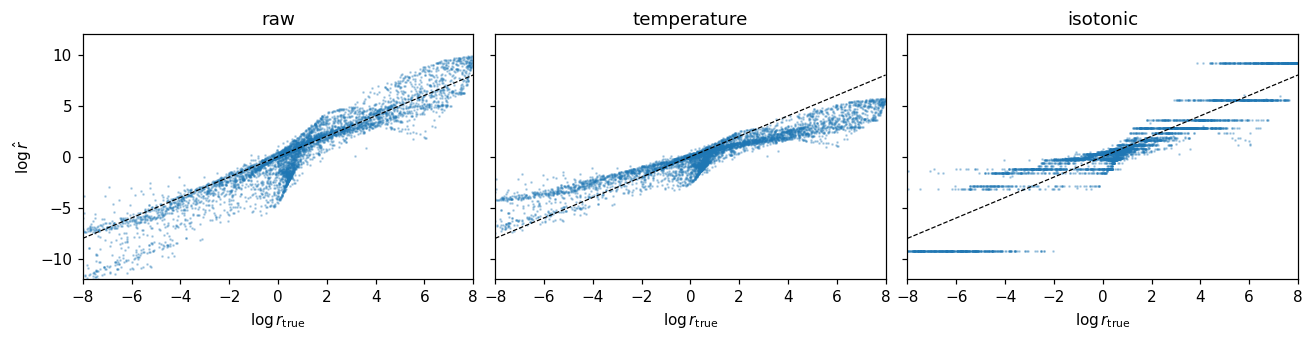

In [5]:
r_true = np.exp(log_p1(x_te) - log_p0(x_te))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True, sharey=True)
sel = rng.permutation(len(y_te))[:6000]
for a, (name, p) in zip(ax, variants.items()):
    p = np.clip(p, 1e-7, 1 - 1e-7)              # saturated probs -> astronomically large, finite ratios
    r_hat = p / (1 - p)
    a.plot(np.log(r_true[sel]), np.log(r_hat[sel]), ".", ms=1.5, alpha=0.3)
    a.plot([-8, 8], [-8, 8], "k--", lw=0.8)
    a.set(title=name, xlabel=r"$\log r_{\rm true}$", xlim=(-8, 8), ylim=(-12, 12))
ax[0].set_ylabel(r"$\log \hat r$")
plt.tight_layout()
# === SOLUTION to the closure exercise ===
bkg = y_te == 0
for name, p in variants.items():
    r_hat = np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7))
    print(f"{name:<14} E_bkg[r_hat] = {r_hat[bkg].mean():.3f}   (exact ratio gives 1)")